In [18]:
import pandas as pd
import matplotlib.pyplot as mp 
import seaborn as sb            
import os

from sklearn.cluster import KMeans

# Cargar el dataset
dataset = pd.read_csv("iris.csv")

dataset.head()

,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


In [21]:
# Seleccionar las columnas en las posiciones del 0 al 3 
# iloc[:, [3,4]] significa: todas las filas (:), y las columnas del 0 al 3
fields = dataset.iloc[:, [0, 1, 2, 3]].values

# Imprimir el resultado para verificar los datos
print(fields)

[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]
 [4.4 2.9 1.4 0.2]
 [4.9 3.1 1.5 0.1]
 [5.4 3.7 1.5 0.2]
 [4.8 3.4 1.6 0.2]
 [4.8 3.  1.4 0.1]
 [4.3 3.  1.1 0.1]
 [5.8 4.  1.2 0.2]
 [5.7 4.4 1.5 0.4]
 [5.4 3.9 1.3 0.4]
 [5.1 3.5 1.4 0.3]
 [5.7 3.8 1.7 0.3]
 [5.1 3.8 1.5 0.3]
 [5.4 3.4 1.7 0.2]
 [5.1 3.7 1.5 0.4]
 [4.6 3.6 1.  0.2]
 [5.1 3.3 1.7 0.5]
 [4.8 3.4 1.9 0.2]
 [5.  3.  1.6 0.2]
 [5.  3.4 1.6 0.4]
 [5.2 3.5 1.5 0.2]
 [5.2 3.4 1.4 0.2]
 [4.7 3.2 1.6 0.2]
 [4.8 3.1 1.6 0.2]
 [5.4 3.4 1.5 0.4]
 [5.2 4.1 1.5 0.1]
 [5.5 4.2 1.4 0.2]
 [4.9 3.1 1.5 0.2]
 [5.  3.2 1.2 0.2]
 [5.5 3.5 1.3 0.2]
 [4.9 3.6 1.4 0.1]
 [4.4 3.  1.3 0.2]
 [5.1 3.4 1.5 0.2]
 [5.  3.5 1.3 0.3]
 [4.5 2.3 1.3 0.3]
 [4.4 3.2 1.3 0.2]
 [5.  3.5 1.6 0.6]
 [5.1 3.8 1.9 0.4]
 [4.8 3.  1.4 0.3]
 [5.1 3.8 1.6 0.2]
 [4.6 3.2 1.4 0.2]
 [5.3 3.7 1.5 0.2]
 [5.  3.3 1.4 0.2]
 [7.  3.2 4.7 1.4]
 [6.4 3.2 4.5 1.5]
 [6.9 3.1 4.

Text(0, 0.5, 'WCSS')

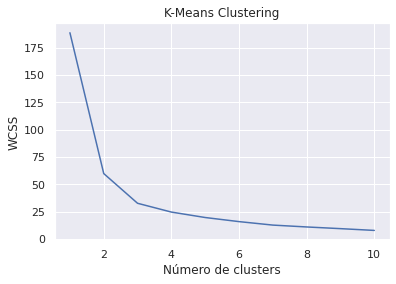

In [24]:
import warnings
warnings.filterwarnings("ignore")

# --- Cálculo de la inercia (WCSS) para diferentes números de clústeres ---
wcss = []
for index in range(1, 11):
    # init='k-means++' es el método estándar para inicializar los centroides de forma inteligente
    kmeans = KMeans(n_clusters=index, init="k-means++", random_state=2)
    kmeans.fit(fields)
    
    # inertia_ nos da el valor de WCSS (Within-Cluster Sum of Squares)
    wcss.append(kmeans.inertia_)

# --- Graficación del "Codo de Jambu" (Elbow Method) ---
sb.set()  # Configura el estilo de los gráficos de seaborn
mp.plot(range(1, 11), wcss) # En tu imagen usas 'mp' como alias de matplotlib.pyplot
mp.title("K-Means Clustering")
mp.xlabel("Número de clusters")
mp.ylabel("WCSS")  # Weighted cluster sum of squares

In [25]:
kmeans = KMeans(n_clusters=3, init="k-means++", random_state=42)

cluster_values = kmeans.fit_predict(fields)

print(cluster_values)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 2 0 2 0 2 2 1 0 2 1 2 2 2 2 0 2 2 2 2 2 2 2 2
 2 0 0 0 2 2 2 2 2 2 2 2 0 2 2 2 2 2 2 1 2 2 2 2 1 2 0 2 0 2 0 0 2 0 0 0 0
 0 0 2 2 0 0 0 0 2 0 2 0 2 0 0 2 2 0 0 0 0 0 2 2 0 0 0 2 0 0 0 2 0 0 0 0 0
 0 2]


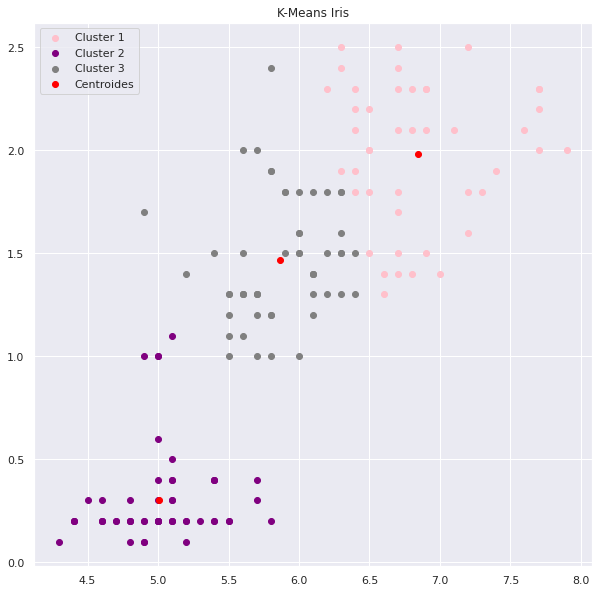

In [27]:
mp.figure(figsize=(10, 10))

mp.scatter(fields[cluster_values == 0, 0], fields[cluster_values == 0, 1], c='pink', label='Cluster 1')
mp.scatter(fields[cluster_values == 1, 0], fields[cluster_values == 1, 1], c='purple', label='Cluster 2')
mp.scatter(fields[cluster_values == 2, 0], fields[cluster_values == 2, 1], c='gray', label='Cluster 3')

mp.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c='red', label='Centroides')

mp.title("K-Means Iris")
mp.legend()

In [29]:
# Criterio de Silueta ("Silhouette")
from sklearn import datasets
from sklearn.metrics import silhouette_score

X = dataset.iloc[:, [0,1,2,3]].to_numpy()

for j in range(2, 12):
    kmeans = KMeans(n_clusters = j, random_state = 42)
    kmeans.fit_predict(X)
    
    score = silhouette_score(X, kmeans.labels_, metric='euclidean')
    print("Score Silhouette;", "k =", j, ":", score)

Score Silhouette; k = 2 : 0.6810461692117465
Score Silhouette; k = 3 : 0.5528190123564102
Score Silhouette; k = 4 : 0.49805050499728815
Score Silhouette; k = 5 : 0.48874888709310654
Score Silhouette; k = 6 : 0.36483400396700366
Score Silhouette; k = 7 : 0.34974816211612186
Score Silhouette; k = 8 : 0.3574536925852728
Score Silhouette; k = 9 : 0.33944886363937105
Score Silhouette; k = 10 : 0.297314497218599
Score Silhouette; k = 11 : 0.31848193024519106


In [30]:
#Algoritmo KMeans aplicado a todas las columnas de nuestra base
#bajo una transformación de PCA

fields2 = dataset.iloc[:, [0,1,2, 3]].values
print(fields2)

[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]
 [4.4 2.9 1.4 0.2]
 [4.9 3.1 1.5 0.1]
 [5.4 3.7 1.5 0.2]
 [4.8 3.4 1.6 0.2]
 [4.8 3.  1.4 0.1]
 [4.3 3.  1.1 0.1]
 [5.8 4.  1.2 0.2]
 [5.7 4.4 1.5 0.4]
 [5.4 3.9 1.3 0.4]
 [5.1 3.5 1.4 0.3]
 [5.7 3.8 1.7 0.3]
 [5.1 3.8 1.5 0.3]
 [5.4 3.4 1.7 0.2]
 [5.1 3.7 1.5 0.4]
 [4.6 3.6 1.  0.2]
 [5.1 3.3 1.7 0.5]
 [4.8 3.4 1.9 0.2]
 [5.  3.  1.6 0.2]
 [5.  3.4 1.6 0.4]
 [5.2 3.5 1.5 0.2]
 [5.2 3.4 1.4 0.2]
 [4.7 3.2 1.6 0.2]
 [4.8 3.1 1.6 0.2]
 [5.4 3.4 1.5 0.4]
 [5.2 4.1 1.5 0.1]
 [5.5 4.2 1.4 0.2]
 [4.9 3.1 1.5 0.2]
 [5.  3.2 1.2 0.2]
 [5.5 3.5 1.3 0.2]
 [4.9 3.6 1.4 0.1]
 [4.4 3.  1.3 0.2]
 [5.1 3.4 1.5 0.2]
 [5.  3.5 1.3 0.3]
 [4.5 2.3 1.3 0.3]
 [4.4 3.2 1.3 0.2]
 [5.  3.5 1.6 0.6]
 [5.1 3.8 1.9 0.4]
 [4.8 3.  1.4 0.3]
 [5.1 3.8 1.6 0.2]
 [4.6 3.2 1.4 0.2]
 [5.3 3.7 1.5 0.2]
 [5.  3.3 1.4 0.2]
 [7.  3.2 4.7 1.4]
 [6.4 3.2 4.5 1.5]
 [6.9 3.1 4.

In [31]:
from sklearn import decomposition

pca = decomposition.PCA(n_components=2)
pca.fit(fields2)
fields2 = pca.transform(fields2)
fields2

array([[-2.68412563,  0.31939725],
       [-2.71414169, -0.17700123],
       [-2.88899057, -0.14494943],
       [-2.74534286, -0.31829898],
       [-2.72871654,  0.32675451],
       [-2.28085963,  0.74133045],
       [-2.82053775, -0.08946138],
       [-2.62614497,  0.16338496],
       [-2.88638273, -0.57831175],
       [-2.6727558 , -0.11377425],
       [-2.50694709,  0.6450689 ],
       [-2.61275523,  0.01472994],
       [-2.78610927, -0.235112  ],
       [-3.22380374, -0.51139459],
       [-2.64475039,  1.17876464],
       [-2.38603903,  1.33806233],
       [-2.62352788,  0.81067951],
       [-2.64829671,  0.31184914],
       [-2.19982032,  0.87283904],
       [-2.5879864 ,  0.51356031],
       [-2.31025622,  0.39134594],
       [-2.54370523,  0.43299606],
       [-3.21593942,  0.13346807],
       [-2.30273318,  0.09870885],
       [-2.35575405, -0.03728186],
       [-2.50666891, -0.14601688],
       [-2.46882007,  0.13095149],
       [-2.56231991,  0.36771886],
       [-2.63953472,

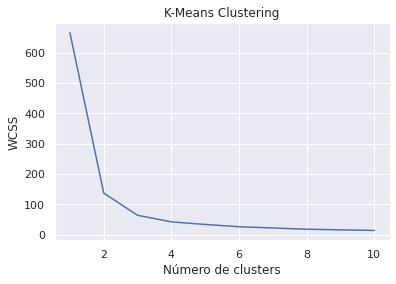

In [32]:
wcss2 = []
for index in range(1, 11):
    kmeans = KMeans(n_clusters = index, init = "k-means++", random_state = 2)
    kmeans.fit(fields2)
    
    wcss2.append(kmeans.inertia_)

sb.set()
mp.plot(range(1, 11), wcss2)
mp.title("K-Means Clustering")
mp.xlabel("Número de clusters")
mp.ylabel("WCSS")
mp.show()

In [33]:
kmeans = KMeans(n_clusters=3, init="k-means++", random_state=42)

cluster_values = kmeans.fit_predict(fields2)

print(cluster_values)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 2 0 0 0 0 2 0 0 0 0
 0 0 2 2 0 0 0 0 2 0 2 0 2 0 0 2 2 0 0 0 0 0 2 0 0 0 0 2 0 0 0 2 0 0 0 2 0
 0 2]


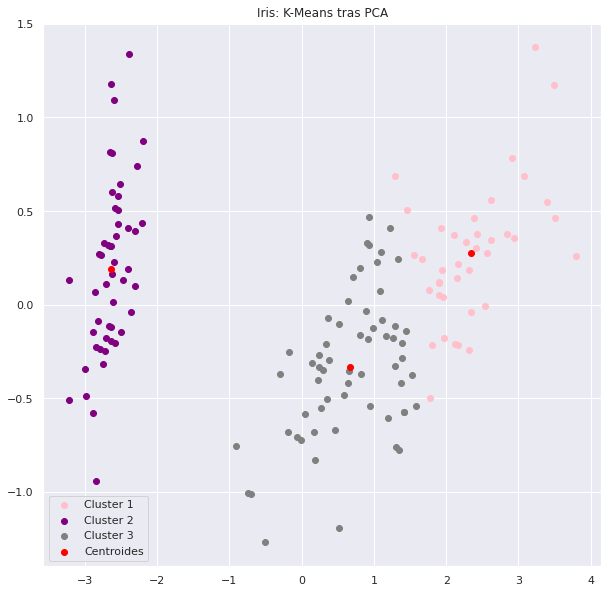

In [34]:
mp.figure(figsize=(10, 10))

mp.scatter(fields2[cluster_values == 0, 0], fields2[cluster_values == 0, 1], c='pink', label='Cluster 1')
mp.scatter(fields2[cluster_values == 1, 0], fields2[cluster_values == 1, 1], c='purple', label='Cluster 2')
mp.scatter(fields2[cluster_values == 2, 0], fields2[cluster_values == 2, 1], c='gray', label='Cluster 3')

mp.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c='red', label='Centroides')

mp.title("Iris: K-Means tras PCA")
mp.legend()

In [36]:
print("INCISO 4) Compare los resultados de los incisos 2) y 3). ¿Obtuvo los mismos resultados de agrupamiento? Comente sobre la ventaja práctica de haber efectuado la transformación por PCA antes de aplicar el algoritmo K-Medias.")
print("En general, los resultados coinciden con 3 clusters, cambian algunas observaciones de clúster tras aplicar PCA, pero")
print("PCA aplasta las 4 dimensiones (ya que usamos 4 variables) a tan solo 2 dimensiones por lo que es más fácil visualizar la separacion de los clusters")

INCISO 4) Compare los resultados de los incisos 2) y 3). ¿Obtuvo los mismos resultados de agrupamiento? Comente sobre la ventaja práctica de haber efectuado la transformación por PCA antes de aplicar el algoritmo K-Medias.
En general, los resultados coinciden con 3 clusters, cambian algunas observaciones de clúster tras aplicar PCA, pero
PCA aplasta las 4 dimensiones (ya que usamos 4 variables) a tan solo 2 dimensiones por lo que es más fácil visualizar la separacion de los clusters
